In [ ]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

pd.set_option('display.float_format', '{:.2f}'.format)

from pathlib import Path

def localizar_edas():
    """Busca Data/raw y Data/processed en Jupyter, Visual Studio Code y Colab.

    Orden de búsqueda: carpeta del notebook, directorio de trabajo y, en Colab, /content.
    Sirve con la estructura Data/raw y Data/processed, y también si los CSV de raw
    o de processed están sueltos en una de esas carpetas (en Colab, junto a sample_data).
    """
    from pathlib import Path
    import json

    saltar = {
        ".config", "sample_data", "drive", ".git", "__pycache__",
        "node_modules", ".ipynb_checkpoints", "site-packages",
    }
    marcas_raw = (
        "artistainfo.json",
        "cancioninfo.json",
        "fecha.json",
        "favoritos.json",
        "listas.json",
        "popularidad.json",
        "features_30_sec.csv",
        "features_3_sec.csv",
    )
    marcas_processed = (
        "cancion.csv",
        "cancion_ids.csv",
        "id_disco.csv",
        "id_genero.csv",
        "fecha_publicacion.csv",
        "fecha_limpio.csv",
        "artistas.csv",
        "artistas_ids.csv",
        "artistas_sql.csv",
        "id_artistas_sql.csv",
        "favoritos.csv",
        "favoritos_eda.csv",
        "listas_canciones.csv",
        "popularidad.csv",
        "features_30_sec.csv",
        "features_3_sec.csv",
    )

    def directorio_notebook():
        try:
            return Path(__vsc_ipynb_file__).resolve().parent
        except NameError:
            pass
        try:
            from urllib.request import urlopen
            try:
                from ipykernel.connect import get_connection_file
            except ImportError:
                from ipykernel import get_connection_file
            conexion = Path(get_connection_file())
            kernel_id = conexion.name.replace("kernel-", "").replace(".json", "")
            servidores = list(conexion.parent.glob("jpserver-*.json"))[:3]
            for servidor in servidores:
                try:
                    info = json.loads(servidor.read_text(encoding="utf-8"))
                except (OSError, json.JSONDecodeError):
                    continue
                url = str(info.get("url", "")).rstrip("/")
                raiz = info.get("root_dir")
                if not url or not raiz:
                    continue
                api = url + "/api/sessions"
                token = info.get("token") or ""
                if token:
                    api += "?token=" + token
                try:
                    with urlopen(api, timeout=0.8) as respuesta:
                        sesiones = json.loads(respuesta.read().decode())
                except Exception:
                    continue
                for sesion in sesiones:
                    kid = (sesion.get("kernel") or {}).get("id")
                    if kid != kernel_id:
                        continue
                    cuaderno = sesion.get("notebook") or {}
                    relativo = cuaderno.get("path") or sesion.get("path")
                    if relativo:
                        return (Path(raiz) / relativo).resolve().parent
        except Exception:
            pass
        return None

    bases = []
    notebook = directorio_notebook()
    if notebook is not None:
        bases.append(notebook)
    cwd = Path.cwd().resolve()
    if cwd not in bases:
        bases.append(cwd)
    content = Path("/content")
    if content.is_dir():
        content = content.resolve()
        if content not in bases:
            bases.append(content)
        drive = content / "drive" / "MyDrive"
        if drive.is_dir() and drive not in bases:
            bases.append(drive)

    def buscar(nombre, marcas):
        opuesta = "processed" if nombre == "raw" else "raw"

        def tiene(carpeta):
            try:
                return any((carpeta / marca).is_file() for marca in marcas)
            except OSError:
                return False

        def nombrada(directorio):
            anidada = directorio / "Data" / nombre
            if tiene(anidada):
                return anidada
            if directorio.name == nombre and tiene(directorio):
                return directorio
            return None

        def hijos(directorio, profundidad, limite):
            if profundidad < 0 or limite[0] <= 0 or not directorio.is_dir():
                return None
            try:
                entradas = list(directorio.iterdir())
            except OSError:
                return None
            for hijo in entradas:
                if not hijo.is_dir() or hijo.name.startswith(".") or hijo.name in saltar:
                    continue
                limite[0] -= 1
                hallazgo = nombrada(hijo)
                if hallazgo is not None:
                    return hallazgo
                if limite[0] <= 0:
                    return None
                hallazgo = hijos(hijo, profundidad - 1, limite)
                if hallazgo is not None:
                    return hallazgo
                if limite[0] <= 0:
                    return None
            return None

        for base in bases:
            if not base.is_dir():
                continue
            hallazgo = nombrada(base)
            if hallazgo is not None:
                return hallazgo
            for padre in list(base.parents)[:6]:
                hallazgo = nombrada(padre)
                if hallazgo is not None:
                    return hallazgo
            profundidad = 3 if base.name in {"content", "MyDrive"} else 2
            hallazgo = hijos(base, profundidad, [400])
            if hallazgo is not None:
                return hallazgo
            if base.name != opuesta and tiene(base):
                return base
        return None

    cruda = buscar("raw", marcas_raw)
    procesados = buscar("processed", marcas_processed)

    if cruda is None and procesados is None:
        raise FileNotFoundError(
            "No se encuentran los datos. "
            "Tiene que existir la carpeta Data/raw o Data/processed, "
            "o los CSV en la carpeta del notebook, en el directorio de trabajo "
            "o, en Colab, en /content junto a sample_data."
        )

    if cruda is not None and procesados is None:
        if cruda.name == "raw":
            procesados = cruda.parent / "processed"
        else:
            procesados = cruda
        procesados.mkdir(parents=True, exist_ok=True)
    elif procesados is not None and cruda is None:
        if procesados.name == "processed":
            cruda = procesados.parent / "raw"
        else:
            cruda = procesados

    return cruda, procesados
DATA_RAW, DATA_PROCESSED = localizar_edas()
print("Raw:", DATA_RAW)
print("Processed:", DATA_PROCESSED)

DATA_PROCESSED.mkdir(parents=True, exist_ok=True)


# Carga de datos

In [ ]:
with open(DATA_RAW / "popularidad.json", "r", encoding="utf-8") as file:
    popularidad = json.load(file)

df = pd.DataFrame(popularidad)
df.head()


,blues.00000.wav,blues.00001.wav,blues.00002.wav,blues.00003.wav,blues.00004.wav,blues.00005.wav,blues.00006.wav,blues.00007.wav,blues.00008.wav,blues.00009.wav,...,rock.00090.wav,rock.00091.wav,rock.00092.wav,rock.00093.wav,rock.00094.wav,rock.00095.wav,rock.00096.wav,rock.00097.wav,rock.00098.wav,rock.00099.wav
reproducciones,"[93664, 7047, 65224, 55270, 55821, 27559, 3481...","[50286, 20395, 39468, 28997, 98892, 22057, 302...","[90466, 78387, 63142, 775, 77078, 13714, 27558...","[91823, -1, 1882, 83507, 35774, 26952, 80873, ...","[10284, 36755, 10518, 16141, 83577, 62614, 232...","[None, 95948, 96694, 88428, 68802, 54575, 4141...","[24145, 35654, 43181, 99980, 1.768740841383048...","[85672, 93436, -1, 34884, 28566, 6507, 36323, ...","[73789, 45787, 498, -0.462246094430109, 87391,...","[55806, 65239, 7495, 38529, 24065, 15878, 7726...",...,"[95014, 85428, 44486, 5912, 48393, 10685, 1.13...","[36579, 78379, 27318, 5305, 97549, 96692, 2514...","[34528, 74890, 14911, 72591, 73236, 63800, 639...","[95731, 54396, 7692, -1, 71367, 4997, 50236, 3...","[75924, 46590, 39446, 8278, -1.381681617849498...","[1402, 31839, 84468, 55410, 99542, 3065, 44563...","[25423, 92875, 28818, 79372, 84973, 1039, 5143...","[70971, 29584, 20839, 4415, 48237, 10839, 2654...","[54670, 27994, 72085, 44841, 63185, 82457, 259...","[69292, 76618, 61460, 60423, -1, 27492, 4832, ..."
numero_reproducciones,267262,333273,-1,1321803,194998,1789804,1730345,1369854,1151629,709089,...,922162,756962,1192307,1480489,343848,-1,1759364,1706309,1038621,1185616


In [ ]:
cancion = pd.read_csv(DATA_PROCESSED / "cancion.csv")
print("Columnas crudas del CSV:", cancion.columns.tolist())

# 'cancion' es el id real de la canción. Si ya existe una columna 'id_cancion'
# suelta/duplicada, la eliminamos antes de renombrar para evitar duplicados.
if 'id_cancion' in cancion.columns:
    print("Aviso: se descarta la columna 'id_cancion' preexistente, se usa 'cancion' como id real.")
    cancion = cancion.drop(columns=['id_cancion'])

df_cancion = cancion.rename(columns={'cancion': 'id_cancion'})
print("Columnas finales de df_cancion:", df_cancion.columns.tolist())
df_cancion.head()


Columnas crudas del CSV: ['id_cancion', 'cancion', 'duracion', 'coste', 'id_genero', 'id_disco', 'id_autor', 'id_discografica']
Aviso: se descarta la columna 'id_cancion' preexistente, se usa 'cancion' como id real.
Columnas finales de df_cancion: ['id_cancion', 'duracion', 'coste', 'id_genero', 'id_disco', 'id_autor', 'id_discografica']


,id_cancion,duracion,coste,id_genero,id_disco,id_autor,id_discografica
0,blues.00000.wav,00:02:18,744.01,1,1,1,1
1,blues.00001.wav,00:02:22,4178.85,1,2,2,2
2,blues.00002.wav,00:01:36,3226.40,1,3,4,3
3,blues.00003.wav,00:01:51,3618.77,1,4,6,4
4,blues.00004.wav,00:03:11,1990.81,1,5,7,5


In [ ]:
df_raw_fecha = pd.read_json(DATA_RAW / "fecha.json")
df_fecha = df_raw_fecha.transpose().reset_index()
df_fecha.columns = ['id_cancion', 'dia_pub', 'mes_pub', 'anio_pub']

df_fecha['dia_pub'] = df_fecha['dia_pub'].fillna(1).astype(int)
df_fecha['mes_pub'] = df_fecha['mes_pub'].fillna(1).astype(int)
df_fecha['anio_pub'] = df_fecha['anio_pub'].fillna(1900)
# Años irrazonablemente bajos -> año por defecto para evitar OutOfBoundsDatetime
df_fecha['anio_pub'] = df_fecha['anio_pub'].apply(lambda x: 1900 if x < 1900 else x).astype(int)

df_fecha['fecha_publicacion'] = pd.to_datetime(
    df_fecha['anio_pub'].astype(str).str.zfill(4) + "-" +
    df_fecha['mes_pub'].astype(str).str.zfill(2) + "-" +
    df_fecha['dia_pub'].astype(str).str.zfill(2),
    errors='coerce', format='%Y-%m-%d'
)

df_fecha.head()


,id_cancion,dia_pub,mes_pub,anio_pub,fecha_publicacion
0,blues.00000.wav,17,10,1900,1900-10-17
1,blues.00001.wav,31,7,2023,2023-07-31
2,blues.00002.wav,14,6,2023,2023-06-14
3,blues.00003.wav,29,5,2023,2023-05-29
4,blues.00004.wav,22,6,1900,1900-06-22


# Preparación de datos

In [ ]:
# Trasponer para tener una fila por canción
df_t = df.T
df_t.index.name = 'id_cancion'
df_t = df_t.reset_index()

# Expandir 'reproducciones' (lista de 30 valores) en columnas dia_1 ... dia_30
dias = pd.DataFrame(
    df_t['reproducciones'].tolist(),
    columns=[f'dia_{i}' for i in range(1, 31)],
    index=df_t['id_cancion']
)

df_correcto = pd.concat([dias, df_t.set_index('id_cancion')['numero_reproducciones']], axis=1)
df_correcto = df_correcto.reset_index()

cols_dias = [f'dia_{i}' for i in range(1, 31)]
columnas_todas = ['numero_reproducciones'] + cols_dias

df_correcto.head()

,id_cancion,dia_1,dia_2,dia_3,dia_4,dia_5,dia_6,dia_7,dia_8,dia_9,...,dia_22,dia_23,dia_24,dia_25,dia_26,dia_27,dia_28,dia_29,dia_30,numero_reproducciones
0,blues.00000.wav,93664.00,7047.00,65224.00,55270.00,55821.00,27559.00,34811.00,4878.00,11864.00,...,26681.00,75288.00,41101.00,99048.00,33960.00,77865.00,43481.00,-1.00,68495.00,267262
1,blues.00001.wav,50286.00,20395.00,39468.00,28997.00,98892.00,22057.00,30220.00,4754.00,66980.00,...,19312.00,57039.00,28638.00,77905.00,90054.00,63121.00,27927.00,85260.00,41753.00,333273
2,blues.00002.wav,90466.00,78387.00,63142.00,775.00,77078.00,13714.00,27558.00,41324.00,49561.00,...,26985.00,48300.00,93387.00,17919.00,NaN,18319.00,64733.00,58397.00,34834.00,-1
3,blues.00003.wav,91823.00,-1.00,1882.00,83507.00,35774.00,26952.00,80873.00,1296.00,62342.00,...,70665.00,67107.00,55232.00,34833.00,53132.00,93305.00,54372.00,90403.00,21242.00,1321803
4,blues.00004.wav,10284.00,36755.00,10518.00,16141.00,83577.00,62614.00,23274.00,26068.00,61880.00,...,39352.00,65893.00,40346.00,82972.00,76992.00,63248.00,27434.00,56810.00,23314.00,194998


In [ ]:
df_correcto["numero_reproducciones"] = pd.to_numeric(
    df_correcto["numero_reproducciones"],
    errors="coerce"
)

In [ ]:
df_correcto.describe()

,dia_1,dia_2,dia_3,dia_4,dia_5,dia_6,dia_7,dia_8,dia_9,dia_10,...,dia_22,dia_23,dia_24,dia_25,dia_26,dia_27,dia_28,dia_29,dia_30,numero_reproducciones
count,977.00,978.00,980.00,983.00,979.00,982.00,990.00,975.00,983.00,988.00,...,980.00,979.00,976.00,975.00,978.00,980.00,976.00,981.00,976.00,983.00
mean,48665.30,47788.54,48810.91,48140.65,46430.13,47578.97,47735.56,45598.62,47853.55,48835.33,...,48729.17,47423.10,47996.03,48103.03,47178.53,46602.77,46552.58,50117.55,48692.39,985938.54
std,30505.27,29859.70,29465.89,30231.67,29998.97,30365.05,30098.58,29186.22,30442.71,29872.25,...,30238.05,30162.61,30165.24,30722.34,29682.88,30408.48,29744.29,30203.95,30221.51,590452.35
min,-1.00,-1.00,-1.00,-1.01,-2.03,-1.00,-1.00,-1.00,-1.00,-1.81,...,-1.01,-1.16,-1.11,-1.39,-1.00,-1.00,-1.00,-1.00,-1.16,-1.00
25%,21790.00,21955.50,22740.75,21447.50,20403.00,20650.00,21040.75,20755.50,18941.00,24569.00,...,22749.50,20635.00,20910.00,20865.50,20718.50,18297.75,21378.25,23776.00,22264.25,476755.00
50%,50286.00,47582.50,49373.50,47316.00,45948.00,47937.00,47341.00,43785.00,48886.00,48841.50,...,48718.00,47836.00,47641.00,47576.00,46932.00,46680.50,46213.00,50846.00,48696.00,1017284.00
75%,74735.00,74109.75,73484.75,75149.00,73103.00,74079.50,74517.50,70339.50,74521.50,74680.00,...,75804.50,73333.00,75095.00,75295.50,72037.25,72672.00,71880.50,77340.00,74926.00,1483134.50
max,99994.00,99830.00,99967.00,99983.00,99945.00,99984.00,99832.00,99845.00,99862.00,99990.00,...,99827.00,99988.00,99996.00,99958.00,99895.00,99953.00,99870.00,99989.00,99963.00,1998066.00


# Validación de consistencia (datos crudos)

Comprobamos si `numero_reproducciones` coincide con la suma de los 30 días, **antes** de aplicar ninguna limpieza.

In [ ]:
def validar_consistencia(df, cols_dias, etiqueta=""):
    """Calcula total_reproducciones (suma de dias, negativos->0), lo compara con
    numero_reproducciones y devuelve el dataframe con las columnas de diferencia
    y la correlacion de Pearson."""
    d = df.copy()
    d['total_reproducciones'] = d[cols_dias].mask(d[cols_dias] < 0, 0).sum(axis=1)

    rep_oficial = d['numero_reproducciones'].mask(d['numero_reproducciones'] < 0, 0)
    d['diferencia_abs'] = (rep_oficial - d['total_reproducciones']).abs()
    d['pct_diferencia'] = np.where(
        d['total_reproducciones'] > 0,
        (d['diferencia_abs'] / d['total_reproducciones']) * 100,
        0
    )

    bins = [-0.01, 0, 5, 10, 25, 50, 100, np.inf]
    labels = ['0% (exacto)', '0.01-5%', '5.01-10%', '10.01-25%',
              '25.01-50%', '50.01-100%', '>100%']
    d['rango_diferencia'] = pd.cut(d['pct_diferencia'], bins=bins, labels=labels)

    corr = d['numero_reproducciones'].corr(d['total_reproducciones'])

    print(f"=== VALIDACIÓN DE CONSISTENCIA {etiqueta} ===")
    print(f"Correlación de Pearson (numero_reproducciones vs total_reproducciones): {corr:.4f}")
    resumen = d['rango_diferencia'].value_counts().sort_index()
    resumen_pct = (resumen / len(d) * 100).round(2)
    print(pd.DataFrame({'Canciones': resumen, '% del total': resumen_pct}))

    return d, corr

df_val_crudo, corr_crudo = validar_consistencia(df_correcto, cols_dias, "(DATOS CRUDOS)")

=== VALIDACIÓN DE CONSISTENCIA (DATOS CRUDOS) ===
Correlación de Pearson (numero_reproducciones vs total_reproducciones): 0.0185
                  Canciones  % del total
rango_diferencia                        
0% (exacto)              17         1.70
0.01-5%                  74         7.40
5.01-10%                 69         6.90
10.01-25%               195        19.50
25.01-50%               258        25.80
50.01-100%              370        37.00
>100%                     0         0.00


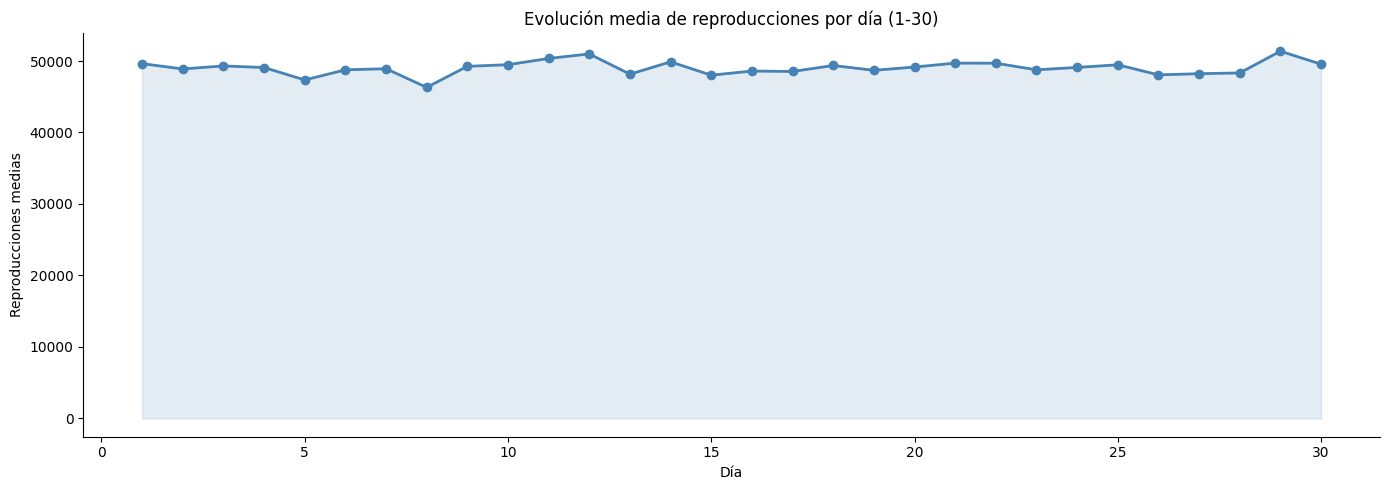

In [ ]:
# Evolución media de reproducciones por día (con negativos excluidos del promedio)
media_por_dia = df_correcto[cols_dias].mask(df_correcto[cols_dias] < 0).mean()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(range(1, 31), media_por_dia.values, marker='o', color='steelblue', linewidth=2)
ax.fill_between(range(1, 31), media_por_dia.values, alpha=0.15, color='steelblue')
ax.set_title('Evolución media de reproducciones por día (1-30)')
ax.set_xlabel('Día')
ax.set_ylabel('Reproducciones medias')
sns.despine()
plt.tight_layout()
plt.show()

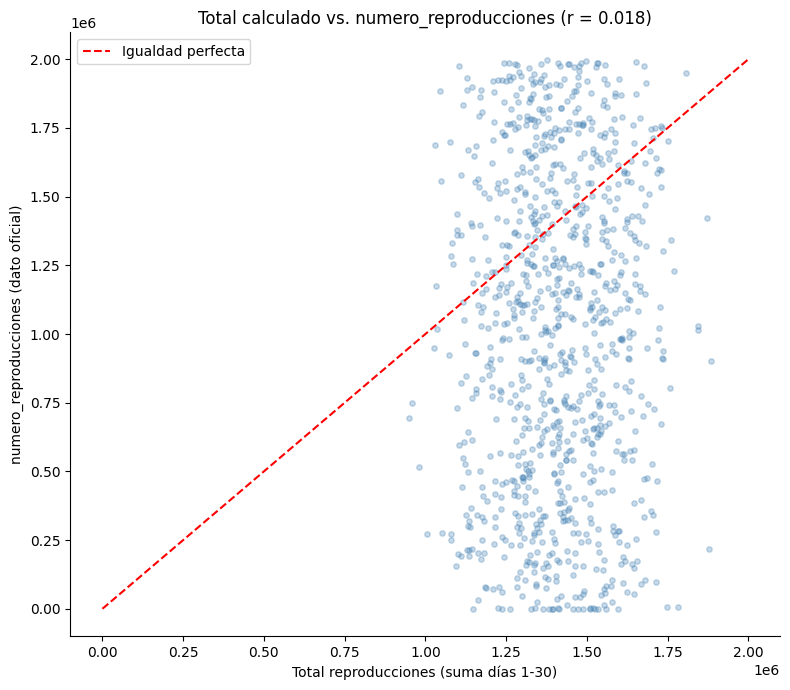

In [ ]:
df_plot = df_val_crudo[(df_val_crudo['numero_reproducciones'] >= 0) & (df_val_crudo['total_reproducciones'] >= 0)]

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(df_plot['total_reproducciones'], df_plot['numero_reproducciones'], alpha=0.3, s=15, color='steelblue')
lim = max(df_plot['total_reproducciones'].max(), df_plot['numero_reproducciones'].max())
ax.plot([0, lim], [0, lim], color='red', linestyle='--', linewidth=1.5, label='Igualdad perfecta')
ax.set_title(f'Total calculado vs. numero_reproducciones (r = {corr_crudo:.3f})')
ax.set_xlabel('Total reproducciones (suma días 1-30)')
ax.set_ylabel('numero_reproducciones (dato oficial)')
ax.legend()
sns.despine()
plt.tight_layout()
plt.show()

**Conclusión:** la correlación es muy cercana a cero. `numero_reproducciones` no parece ser la suma de los 30 días registrados: probablemente sea una métrica distinta (p. ej. una ventana temporal diferente) y no debe usarse para "corregir" o sustituir la suma de días, ni viceversa, sin más contexto.

# Análisis de valores atípicos (negativos)

##  `numero_reproducciones`

In [ ]:
col = 'numero_reproducciones'
negativos_rep = df_correcto[df_correcto[col] < 0]

print("¿Valores negativos únicos?:", sorted(negativos_rep[col].unique()))
print("¿Son únicamente -1?:", set(negativos_rep[col].unique()) == {-1})

¿Valores negativos únicos?: [-1, -0.5912926290597968]
¿Son únicamente -1?: False


In [ ]:
total_filas = len(df_correcto)
cant_atipicos = len(negativos_rep)
pct_atipicos = cant_atipicos / total_filas * 100
print(f"Atípicos en numero_reproducciones: {cant_atipicos} de {total_filas} ({pct_atipicos:.2f}%)")

Atípicos en numero_reproducciones: 21 de 1000 (2.10%)


In [ ]:
solo_neg = df_correcto.loc[df_correcto[col] < 0, col]
todos = df_correcto[col].dropna()

media_glob, mediana_glob, std_glob = todos.mean(), todos.median(), todos.std()
media_neg, mediana_neg, std_neg = solo_neg.mean(), solo_neg.median(), solo_neg.std()

print("[TODOS]     Media: {:.2f} | Mediana: {:.2f} | σ: {:.2f}".format(media_glob, mediana_glob, std_glob))
print("[NEGATIVOS] Media: {:.2f} | Mediana: {:.2f} | σ: {:.2f}".format(media_neg, mediana_neg, std_neg))

limite_inf_1sigma = media_glob - std_glob
print(f"\nLímite inferior a 1σ (media - σ, global): {limite_inf_1sigma:.2f}")
print(f"¿Todos los negativos caen fuera de 1σ?: {(solo_neg < limite_inf_1sigma).all()}")

[TODOS]     Media: 985938.54 | Mediana: 1017284.00 | σ: 590452.35
[NEGATIVOS] Media: -0.98 | Mediana: -1.00 | σ: 0.09

Límite inferior a 1σ (media - σ, global): 395486.18
¿Todos los negativos caen fuera de 1σ?: True


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

datos = df_correcto["numero_reproducciones"].dropna()

# Crear intervalos
intervalos = pd.cut(
    datos,
    bins=[-float("inf"), -1, 0, 100, 1000, 10000, 100000, 1000000, float("inf")]
)

# Contar cuántos valores hay en cada intervalo
frecuencias = intervalos.value_counts().sort_index()

print(frecuencias)

numero_reproducciones
(-inf, -1.0]              20
(-1.0, 0.0]                1
(0.0, 100.0]              17
(100.0, 1000.0]            0
(1000.0, 10000.0]          7
(10000.0, 100000.0]       31
(100000.0, 1000000.0]    408
(1000000.0, inf]         499
Name: count, dtype: int64


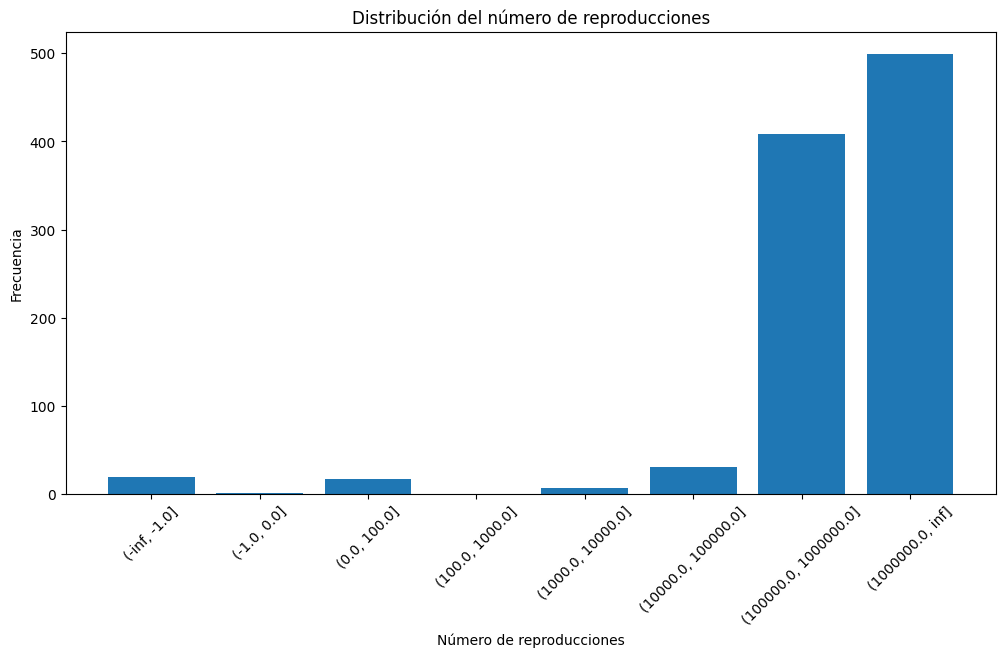

In [ ]:
plt.figure(figsize=(12, 6))

plt.bar(
    frecuencias.index.astype(str),
    frecuencias.values
)

plt.xlabel("Número de reproducciones")
plt.ylabel("Frecuencia")
plt.title("Distribución del número de reproducciones")

plt.xticks(rotation=45)

plt.show()

Debido al volumen de datos, he agrupado los datos por rangos. Vemos que hay pocos valores negativos (21) y el resto de los valores se encuentran una pequeña parte entre 0 a 100, otra entre 1.000 a 10.000 y otra entre 10.000 y 100.000. Concrentrandose un mayor volumen de los datos entre los 100.000 y mayores de 1.000.000 en el dato total de reproducciones en un mes.

=== NEGATIVOS DE numero_reproducciones POR GÉNERO ===
id_genero
9     5
6     4
5     3
2     2
1     2
7     2
8     2
10    1
Name: count, dtype: int64

=== NEGATIVOS DE numero_reproducciones POR AUTOR ===
id_autor
4      1
31     1
37     1
65     1
152    1
141    1
151    1
176    1
195    1
188    1
196    1
222    1
219    1
237    1
254    1
270    1
272    1
290    1
288    1
289    1
306    1
Name: count, dtype: int64

=== NEGATIVOS DE numero_reproducciones POR DISCOGRÁFICA ===
id_discografica
1     3
3     2
10    2
18    2
21    1
11    1
7     1
28    1
14    1
26    1
29    1
6     1
30    1
8     1
9     1
25    1
Name: count, dtype: int64


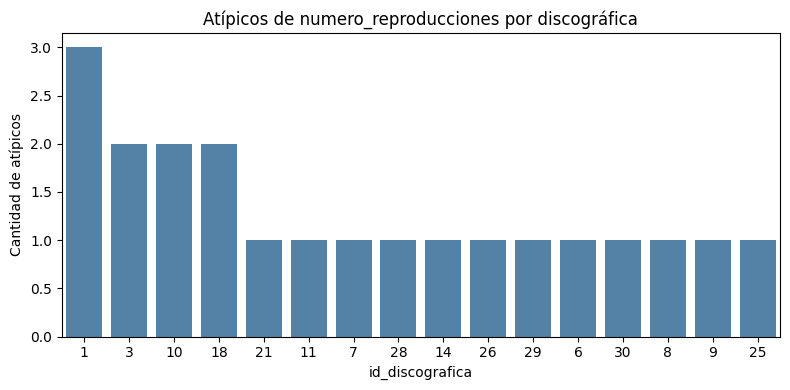

In [ ]:
# Localización de los atípicos: género, autor y discográfica -- SOLO numero_reproducciones
col_genero = 'id_genero' if 'id_genero' in df_cancion.columns else 'genero'
col_autor = 'id_autor' if 'id_autor' in df_cancion.columns else 'autor'
col_disco = 'id_discografica' if 'id_discografica' in df_cancion.columns else (
    'id_disco' if 'id_disco' in df_cancion.columns else None)

negativos_rep_info = negativos_rep.merge(df_cancion, on='id_cancion', how='left')

print("=== NEGATIVOS DE numero_reproducciones POR GÉNERO ===")
print(negativos_rep_info[col_genero].value_counts())

print("\n=== NEGATIVOS DE numero_reproducciones POR AUTOR ===")
print(negativos_rep_info[col_autor].value_counts())

if col_disco:
    print("\n=== NEGATIVOS DE numero_reproducciones POR DISCOGRÁFICA ===")
    conteo_disco = negativos_rep_info[col_disco].value_counts()
    print(conteo_disco)

    plt.figure(figsize=(8, 4))
    sns.barplot(x=conteo_disco.index.astype(str), y=conteo_disco.values, color='steelblue')
    plt.title('Atípicos de numero_reproducciones por discográfica')
    plt.xlabel(col_disco)
    plt.ylabel('Cantidad de atípicos')
    plt.tight_layout()
    plt.show()
else:
    print("No se encontró columna de discográfica en df_cancion; revisar nombre de columna.")

Conclusiones
*1. Volumen bajo pero disperso: hay un total de 21 registros con valores negativos en numero_reproducciones, una cantidad pequeña respecto al dataset completo, lo que confirma por qué no eran visibles en el histograma general.
*2. Por género: los negativos no se concentran en un solo género. El género 9 es el que más registros negativos tiene (5), seguido del 6 (4), pero el resto está repartido entre 1 y 3 casos por género (2, 5, 7, 8, 10, 1). Esto sugiere que no hay un género particular que explique el problema — es un error transversal.
*3. Por autor: aún más disperso — prácticamente cada autor afectado tiene solo 1 registro negativo (21 autores distintos, cada uno con count=1). Esto es una señal fuerte de que no es un problema sistemático de un artista específico, sino errores puntuales y aislados en la carga de datos.
*4. Por discográfica: patrón similar, con distribución dispersa entre 16 discográficas distintas. La discográfica 1 tiene el mayor número (3), pero la mayoría tiene solo 1 o 2 casos.
*5. Conclusión general: la evidencia apunta a que estos valores negativos no responden a un patrón de negocio real (por ejemplo, un género o sello que sistemáticamente reporta mal sus datos), sino que son errores aleatorios de captura o procesamiento de datos — probablemente fallos puntuales en el pipeline de datos, sensores/APIs de streaming, o inserciones manuales erróneas.
*6. Recomendación: dado que son solo 21 registros y están dispersos sin patrón claro, lo más razonable es tratarlos como errores y no como información de negocio válida.




## Columnas de día (`dia_1` ... `dia_30`)

In [ ]:
mascara_neg_dias = df_correcto[cols_dias] < 0
valores_neg_dias = df_correcto[cols_dias].values[mascara_neg_dias.values]
valores_neg_dias = valores_neg_dias[~np.isnan(valores_neg_dias)]

print("Valores negativos únicos en columnas día:", np.unique(valores_neg_dias))
print("¿Son únicamente -1?:", set(np.unique(valores_neg_dias)) == {-1})

Valores negativos únicos en columnas día: [-2.02550621e+00 -1.81038209e+00 -1.72056970e+00 -1.61789585e+00
 -1.39253140e+00 -1.38168162e+00 -1.37965728e+00 -1.36683707e+00
 -1.33392564e+00 -1.15862465e+00 -1.15653727e+00 -1.11280870e+00
 -1.01155208e+00 -1.00630020e+00 -1.00000000e+00 -9.49231545e-01
 -9.25241784e-01 -9.09759711e-01 -8.27232271e-01 -8.14230710e-01
 -7.74008729e-01 -7.73979578e-01 -7.46356308e-01 -7.14164039e-01
 -7.04733696e-01 -7.02438685e-01 -6.77995896e-01 -6.62580087e-01
 -6.49042015e-01 -6.37216222e-01 -6.31228610e-01 -5.89613362e-01
 -5.62172422e-01 -5.48850937e-01 -5.39268184e-01 -5.20609715e-01
 -5.16668498e-01 -5.00835200e-01 -4.85715051e-01 -4.84530983e-01
 -4.83277945e-01 -4.79767539e-01 -4.66947797e-01 -4.66484573e-01
 -4.62246094e-01 -4.60341241e-01 -4.32690438e-01 -4.10590879e-01
 -3.76910137e-01 -3.75821404e-01 -3.75557615e-01 -3.73992261e-01
 -3.73795032e-01 -3.71551700e-01 -3.70990850e-01 -3.64962401e-01
 -3.52904594e-01 -3.40696268e-01 -3.37397384e-01

No solamente hay valores -1. Hay otros negativos.

In [ ]:
total_celdas = len(df_correcto) * len(cols_dias)
total_atipicos_dias = int(mascara_neg_dias.sum().sum())
pct_dias = total_atipicos_dias / total_celdas * 100
print(f"Atípicos en columnas día: {total_atipicos_dias} de {total_celdas} celdas ({pct_dias:.2f}%)")

Atípicos en columnas día: 695 de 30000 celdas (2.32%)


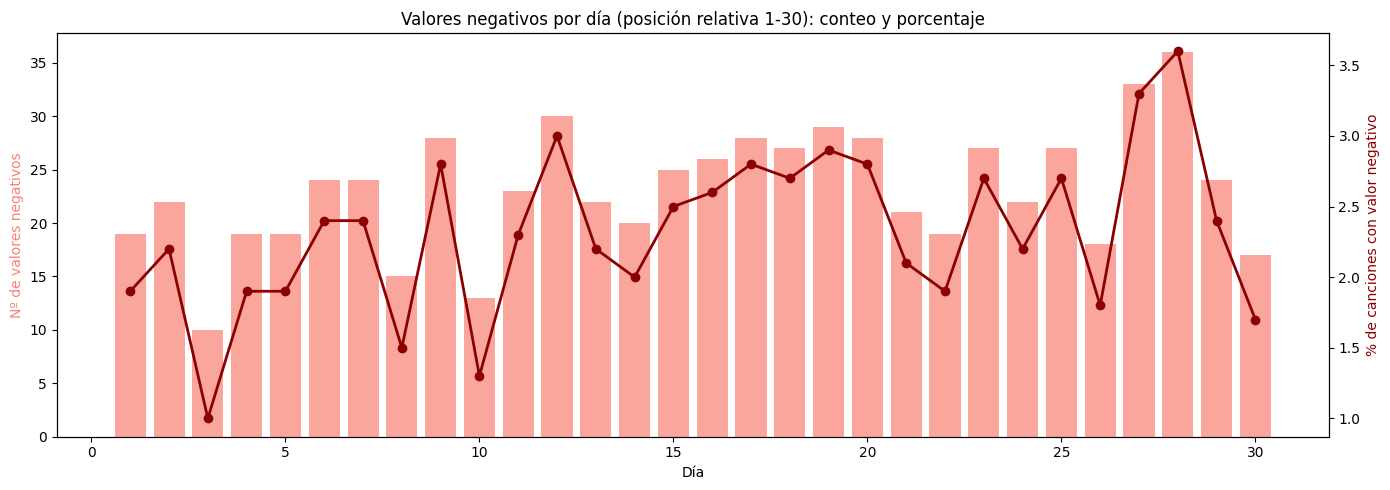

In [ ]:
conteo_neg = mascara_neg_dias.sum().values
pct_neg = (mascara_neg_dias.mean() * 100).values
dias_idx = list(range(1, 31))

fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.bar(dias_idx, conteo_neg, color='salmon', alpha=0.7, label='Conteo negativos')
ax1.set_xlabel('Día')
ax1.set_ylabel('Nº de valores negativos', color='salmon')

ax2 = ax1.twinx()
ax2.plot(dias_idx, pct_neg, color='darkred', linewidth=2, marker='o', label='% negativos')
ax2.set_ylabel('% de canciones con valor negativo', color='darkred')

ax1.set_title('Valores negativos por día (posición relativa 1-30): conteo y porcentaje')
fig.tight_layout()
plt.show()

El análisis de valores negativos en numero_reproducciones a lo largo de 30 días revela una tendencia creciente y preocupante: el porcentaje diario de canciones afectadas pasa de aproximadamente 1.7% en el día 1 a un pico de 3.6% en el día 28, lo que sugiere que el problema no es un error aislado, sino que se agrava progresivamente con el tiempo. El punto más crítico se concentra en los días 27-28, donde se registran hasta 36 valores negativos en un solo día, muy por encima del resto de la serie, lo que apunta a un posible evento puntual —como un despliegue, migración o fallo en el pipeline de datos— que debería investigarse cruzando estas fechas con el changelog técnico. Pero también vemos que desde el 28, los datos vuelven a sufrir un descenso. Además, se observan valles recurrentes en los días 3, 10 y 26, un patrón que podría estar relacionado con estacionalidad semanal. Es importante destacar que el conteo absoluto y el porcentaje relativo se mueven de forma prácticamente idéntica, lo que indica que el aumento de negativos no se debe simplemente a un mayor volumen de datos, sino a un incremento real en la tasa de error del sistema.

In [ ]:
# Localización de los atípicos de columnas día: género, autor y discográfica -- SOLO días
from collections import Counter

contador = Counter()
for c in cols_dias:
    mask = df_correcto[c] < 0
    if mask.any():
        contador.update(df_correcto.loc[mask, 'id_cancion'].values)

df_neg_dias_por_cancion = pd.DataFrame(contador.items(), columns=['id_cancion', 'veces_con_negativo_en_dias'])
df_neg_dias_por_cancion = df_neg_dias_por_cancion.merge(df_cancion, on='id_cancion', how='left')

print("=== NEGATIVOS EN COLUMNAS DÍA POR GÉNERO ===")
print(df_neg_dias_por_cancion.groupby(col_genero)['veces_con_negativo_en_dias'].sum().sort_values(ascending=False))

print("\n=== NEGATIVOS EN COLUMNAS DÍA POR AUTOR ===")
print(df_neg_dias_por_cancion.groupby(col_autor)['veces_con_negativo_en_dias'].sum().sort_values(ascending=False).head(20))

if col_disco:
    print("\n=== NEGATIVOS EN COLUMNAS DÍA POR DISCOGRÁFICA ===")
    conteo_disco_dias = df_neg_dias_por_cancion.groupby(col_disco)['veces_con_negativo_en_dias'].sum().sort_values(ascending=False)
    print(conteo_disco_dias)

=== NEGATIVOS EN COLUMNAS DÍA POR GÉNERO ===
id_genero
9     79
4     79
7     75
5     72
10    72
3     67
6     66
1     64
8     64
2     57
Name: veces_con_negativo_en_dias, dtype: int64

=== NEGATIVOS EN COLUMNAS DÍA POR AUTOR ===
id_autor
282    8
104    8
121    8
3      7
153    7
72     7
300    7
211    7
223    6
145    6
57     6
25     6
272    6
265    6
193    6
203    6
51     5
55     5
279    5
45     5
Name: veces_con_negativo_en_dias, dtype: int64

=== NEGATIVOS EN COLUMNAS DÍA POR DISCOGRÁFICA ===
id_discografica
3     63
19    32
9     31
11    30
26    29
27    26
15    25
4     24
6     24
1     24
25    23
22    22
29    21
24    21
14    21
7     20
2     20
8     19
30    19
31    19
5     18
17    17
28    17
32    17
10    16
12    16
20    15
13    15
21    14
23    13
16    12
18    12
Name: veces_con_negativo_en_dias, dtype: int64


*Por género: los valores están muy concentrados en un rango estrecho (57 a 79 ), con una diferencia máxima de solo 22 puntos entre el género más afectado (9 y 4, empatados en 79) y el menos afectado (2, con 57). Esto indica una distribución prácticamente uniforme entre géneros, sin un outlier claro — el problema no está sesgado hacia un tipo de música en particular, sino que afecta a todo el catálogo de forma pareja.

*Por autor: se observa un patrón de alta dispersión con baja intensidad individual. Los valores más altos (8 ocurrencias) corresponden solo a 3 autores (282, 104, 121), y a partir de ahí los conteos descienden de forma gradual y escalonada (7, 6, 5...) repartidos entre muchos autores distintos. Ningún autor concentra un volumen desproporcionado respecto a los demás — es un patrón de "cola larga" plana, coherente con un problema que golpea de forma amplia y superficial en lugar de repetirse intensamente sobre artistas concretos.

*Por discográfica: aquí aparece el patrón más distintivo de los tres. La discográfica 3 destaca claramente con 63 ocurrencias, casi el doble que la segunda más afectada (19, con 32). Después de ese salto, el resto de discográficas forma una cola descendente suave y continua (32 → 31 → 30 → 29... hasta 12), sin más saltos abruptos.

=== ATÍPICOS DE COLUMNAS DÍA POR DÍA DE LA SEMANA REAL ===
dia_semana
Monday       100
Tuesday       85
Wednesday     73
Thursday      93
Friday        87
Saturday      83
Sunday       104
Name: id_cancion, dtype: int64


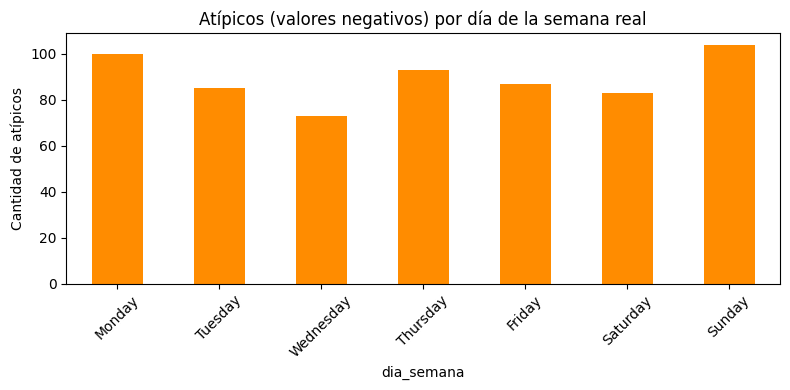

In [ ]:
# NUEVO: ¿los negativos caen siempre en el mismo día de la semana (lunes, etc.)?
# dia_N = N-esimo dia despues de la publicacion -> fecha_real = fecha_publicacion + (N-1) dias
df_dias_largo = df_correcto[['id_cancion'] + cols_dias].melt(
    id_vars='id_cancion', var_name='dia_col', value_name='reproducciones_dia'
)
df_dias_largo['n_dia'] = df_dias_largo['dia_col'].str.replace('dia_', '', regex=False).astype(int)

df_dias_largo = df_dias_largo.merge(df_fecha[['id_cancion', 'fecha_publicacion']], on='id_cancion', how='left')
df_dias_largo['fecha_real'] = df_dias_largo['fecha_publicacion'] + pd.to_timedelta(df_dias_largo['n_dia'] - 1, unit='D')
df_dias_largo['dia_semana'] = df_dias_largo['fecha_real'].dt.day_name()

atipicos_por_semana = (
    df_dias_largo[df_dias_largo['reproducciones_dia'] < 0]
    .groupby('dia_semana')['id_cancion']
    .count()
    .reindex(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])
)

print("=== ATÍPICOS DE COLUMNAS DÍA POR DÍA DE LA SEMANA REAL ===")
print(atipicos_por_semana)

plt.figure(figsize=(8, 4))
atipicos_por_semana.plot(kind='bar', color='darkorange')
plt.title('Atípicos (valores negativos) por día de la semana real')
plt.ylabel('Cantidad de atípicos')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Los datos a nivel semanal no sufren mucha diferencia en los datos. Los domingos y lunes tienen un dato ligeramente mejor por lo que entendemos que es aquí donde se están registrando más valores atípicos y habría que analizar incidencias durante estos días para intentar detectar el problema real de la recolección de datos.

## Merge con fecha de publicación: ¿coincide con septiembre 2025?

In [ ]:
df_popularidadycancion = df_cancion.merge(df_correcto, on='id_cancion', how='left')
df_merged_analysis = df_popularidadycancion.merge(
    df_fecha[['id_cancion', 'fecha_publicacion']], on='id_cancion', how='left'
)

df_merged_analysis['es_septiembre_2025'] = (
    (df_merged_analysis['fecha_publicacion'].dt.year == 2025) &
    (df_merged_analysis['fecha_publicacion'].dt.month == 9)
)

df_merged_analysis['tipo_valor'] = np.where(
    df_merged_analysis['numero_reproducciones'] < 0, 'Atípico (< 0)', 'Normal (>= 0)'
)

tabla_cruzada = pd.crosstab(
    df_merged_analysis['es_septiembre_2025'], df_merged_analysis['tipo_valor'],
    rownames=['¿Publicada en sept. 2025?'], colnames=['numero_reproducciones']
)
print(tabla_cruzada)

numero_reproducciones      Atípico (< 0)  Normal (>= 0)
¿Publicada en sept. 2025?                              
False                                 21            979


# Propuesta de limpieza

## `numero_reproducciones` — comparativa visual de estrategias

Estrategias comparadas: desplazar la distribución, espejo (valor absoluto), poner a cero, sustituir por la mediana y sustituir por la media de los valores positivos.

Vamos a usar una **Escala logarítmica en el eje X**

La escala logarítmica permite representar mejor variables cuyos valores abarcan varios órdenes de magnitud. En lugar de aumentar de forma lineal (1, 2, 3, 4...), el eje aumenta multiplicativamente (1, 10, 100, 1.000...).

En numero_reproducciones es útil porque puede haber valores muy pequeños y otros extremadamente grandes. Con una escala lineal, los valores pequeños pueden quedar comprimidos cerca de 0.

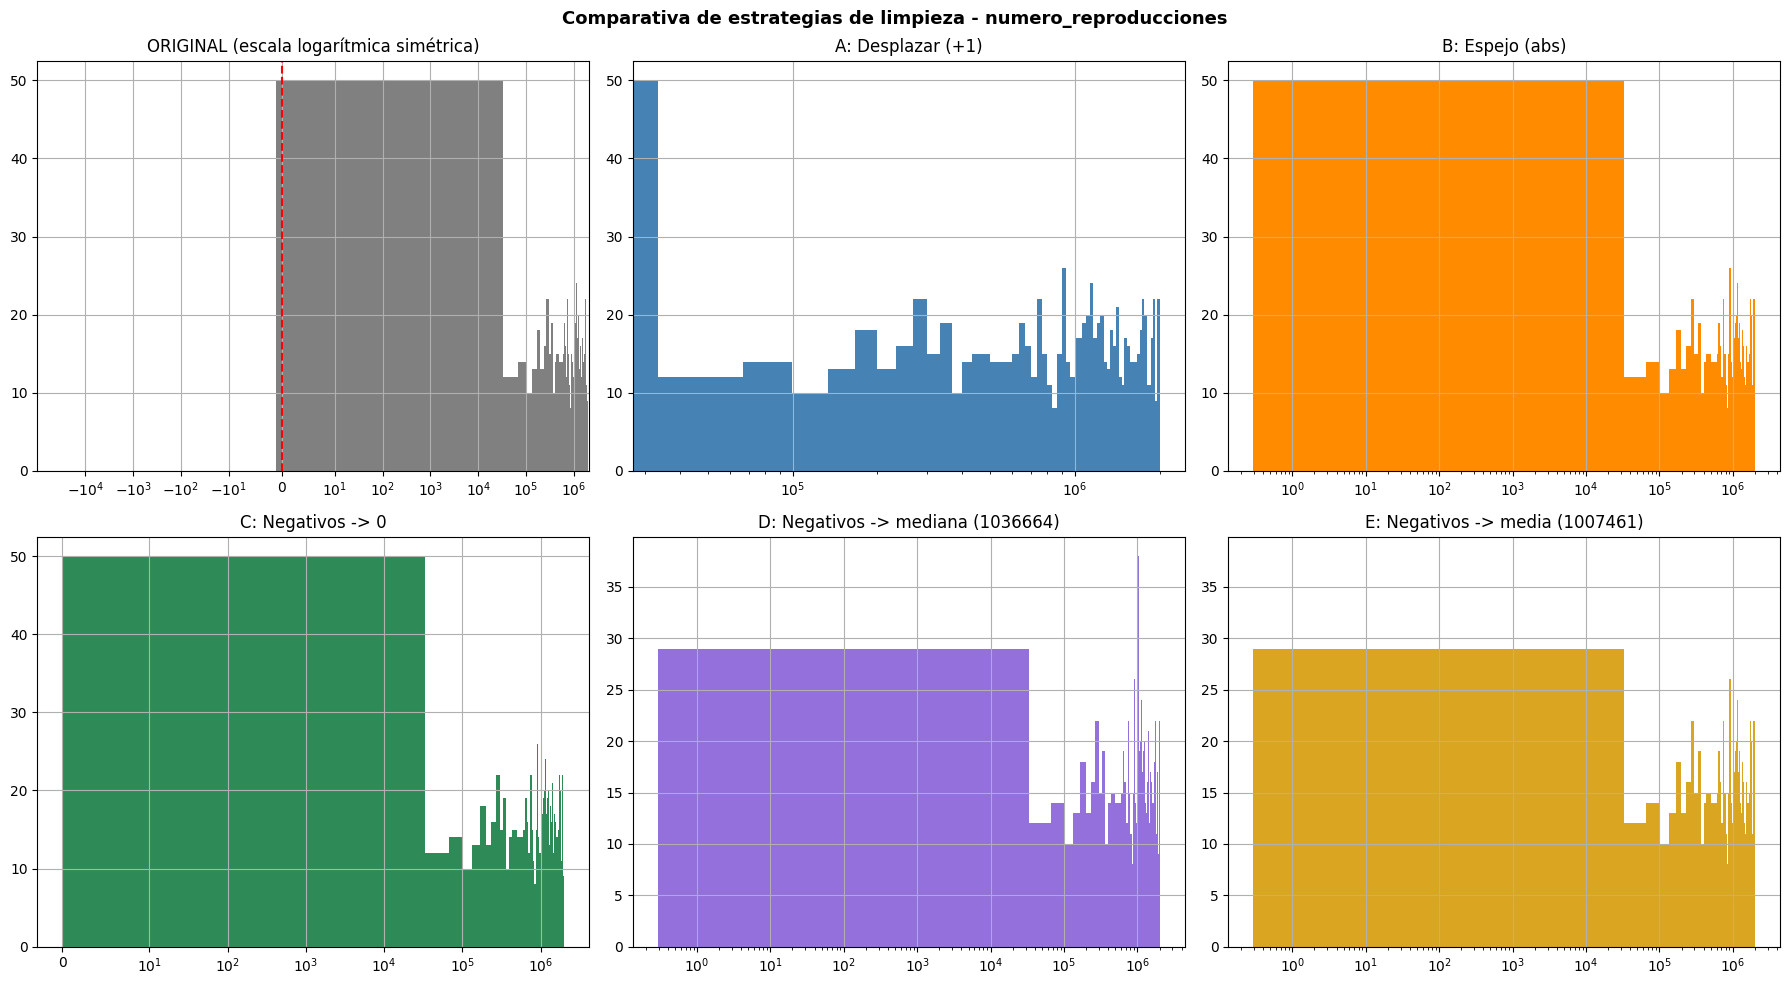

Negativos totales: 21 (2.14%)
Valor mínimo: -1
Mediana positivos: 1036664 | Media positivos: 1007461


In [ ]:
serie_original = df_correcto['numero_reproducciones'].dropna()

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# ---------------------------------------------------------
# ORIGINAL - ESCALA SYMLOG
# ---------------------------------------------------------
serie_original.hist(
    ax=axes[0, 0],
    bins=60,
    color='gray'
)

axes[0, 0].set_title('ORIGINAL (escala logarítmica simétrica)')
axes[0, 0].axvline(
    0,
    color='red',
    linestyle='--',
    linewidth=1.5
)

# Escala logarítmica que permite negativos y cero
axes[0, 0].set_xscale(
    'symlog',
    linthresh=10
)

# ---------------------------------------------------------
# A: Desplazar
# ---------------------------------------------------------
shift_val = abs(serie_original.min())

(serie_original + shift_val).hist(
    ax=axes[0, 1],
    bins=60,
    color='steelblue'
)

axes[0, 1].set_title(
    f'A: Desplazar (+{shift_val:.0f})'
)

axes[0, 1].set_xscale('log')

# ---------------------------------------------------------
# B: Espejo
# ---------------------------------------------------------
serie_original.abs().hist(
    ax=axes[0, 2],
    bins=60,
    color='darkorange'
)

axes[0, 2].set_title('B: Espejo (abs)')
axes[0, 2].set_xscale('log')

# ---------------------------------------------------------
# C: Negativos -> 0
# ---------------------------------------------------------
serie_original.clip(lower=0).hist(
    ax=axes[1, 0],
    bins=60,
    color='seagreen'
)

axes[1, 0].set_title('C: Negativos -> 0')
axes[1, 0].set_xscale('symlog', linthresh=10)

# ---------------------------------------------------------
# D: Negativos -> mediana
# ---------------------------------------------------------
mediana_pos = serie_original[
    serie_original >= 0
].median()

serie_mediana = serie_original.where(
    serie_original >= 0,
    mediana_pos
)

serie_mediana.hist(
    ax=axes[1, 1],
    bins=60,
    color='mediumpurple'
)

axes[1, 1].set_title(
    f'D: Negativos -> mediana ({mediana_pos:.0f})'
)

axes[1, 1].set_xscale('log')

# ---------------------------------------------------------
# E: Negativos -> media
# ---------------------------------------------------------
media_pos = serie_original[
    serie_original >= 0
].mean()

serie_media = serie_original.where(
    serie_original >= 0,
    media_pos
)

serie_media.hist(
    ax=axes[1, 2],
    bins=60,
    color='goldenrod'
)

axes[1, 2].set_title(
    f'E: Negativos -> media ({media_pos:.0f})'
)

axes[1, 2].set_xscale('log')

# ---------------------------------------------------------
# Título
# ---------------------------------------------------------
plt.suptitle(
    'Comparativa de estrategias de limpieza - numero_reproducciones',
    fontsize=13,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Estadísticas
# ---------------------------------------------------------
print(
    f"Negativos totales: "
    f"{(serie_original < 0).sum()} "
    f"({(serie_original < 0).mean()*100:.2f}%)"
)

print(
    f"Valor mínimo: {serie_original.min():.0f}"
)

print(
    f"Mediana positivos: {mediana_pos:.0f} | "
    f"Media positivos: {media_pos:.0f}"
)

Con esta visualización intentamos analizar cuál es la mejor estrategia para la limpieza de los valores negativos. Vemos que el uso de la mediana,  media o desplazar altera los datos ligeramente. Vemos como una mejor opción igualarlos a 0 o convertir los negativos en positivos.

En los dos casos, la distribución de fondo se mantiene, porque el volumen de negativos es tan bajo (21 registros) que cualquier tratamiento sobre ellos apenas mueve la distribución general.

## Columnas de día — comparativa visual de estrategias

Aplicamos la misma comparación (cero / mediana / media) sobre el conjunto de valores de las 30 columnas de día.

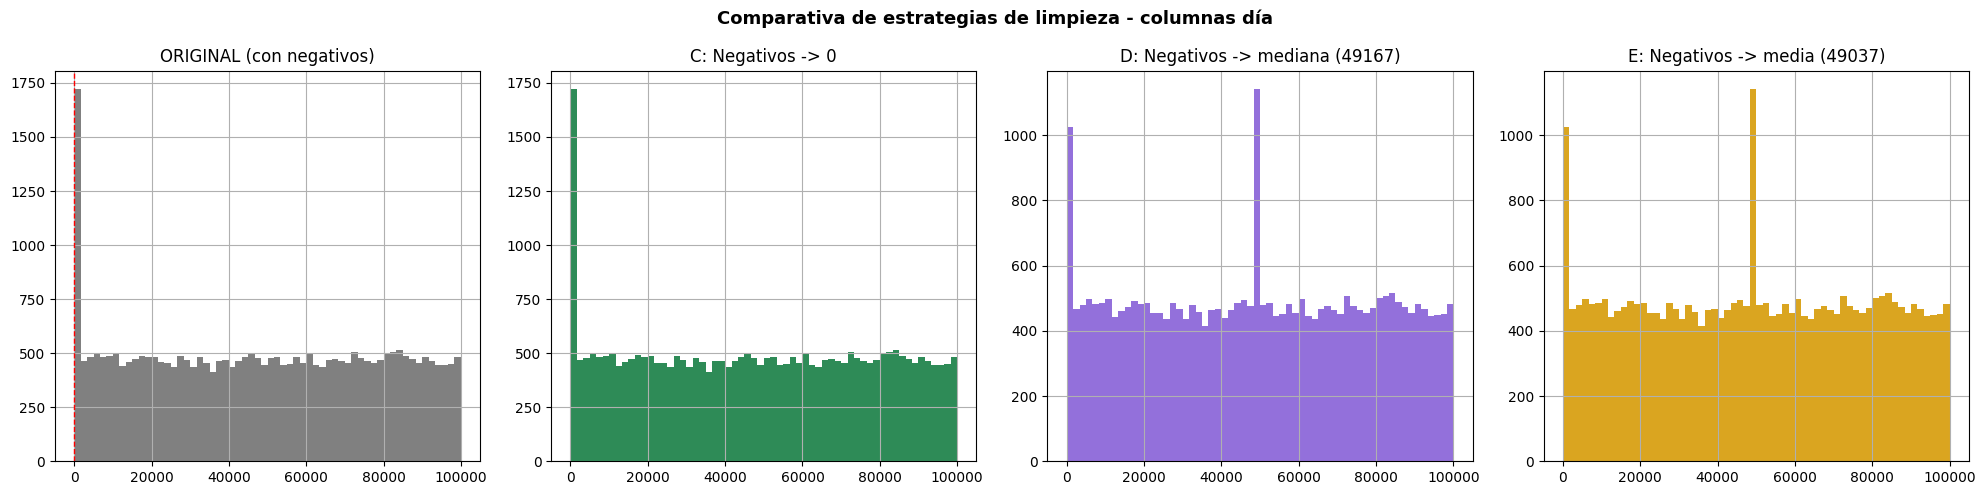

In [ ]:
valores_dias_original = df_correcto[cols_dias].values.flatten()
valores_dias_original = valores_dias_original[~np.isnan(valores_dias_original)]
serie_dias = pd.Series(valores_dias_original)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

serie_dias.hist(ax=axes[0], bins=60, color='gray')
axes[0].set_title('ORIGINAL (con negativos)')
axes[0].axvline(0, color='red', linestyle='--', linewidth=1)

serie_dias.clip(lower=0).hist(ax=axes[1], bins=60, color='seagreen')
axes[1].set_title('C: Negativos -> 0')

mediana_dias_pos = serie_dias[serie_dias >= 0].median()
serie_dias.where(serie_dias >= 0, mediana_dias_pos).hist(ax=axes[2], bins=60, color='mediumpurple')
axes[2].set_title(f'D: Negativos -> mediana ({mediana_dias_pos:.0f})')

media_dias_pos = serie_dias[serie_dias >= 0].mean()
serie_dias.where(serie_dias >= 0, media_dias_pos).hist(ax=axes[3], bins=60, color='goldenrod')
axes[3].set_title(f'E: Negativos -> media ({media_dias_pos:.0f})')

plt.suptitle('Comparativa de estrategias de limpieza - columnas día', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

**Elegimos:** al igual que en `numero_reproducciones`, mantenemos **poner a cero** para las columnas de día, por consistencia entre ambas tablas y porque no distorsiona la distribución original.

*Nota: Aunque no se aprecien los valores negativos en los gráficos y parece que son solo 0 es consecuencia de la visualización y del número tan reducido de los negativos son respecto al número del resto de valores.

## Aplicar la limpieza elegida

In [ ]:
df_limpio = df_correcto.copy()

# Estrategia elegida: negativos -> 0, tanto en columnas día como en numero_reproducciones
df_limpio[cols_dias] = df_limpio[cols_dias].clip(lower=0)
df_limpio['numero_reproducciones'] = df_limpio['numero_reproducciones'].clip(lower=0)

df_limpio.describe()

,dia_1,dia_2,dia_3,dia_4,dia_5,dia_6,dia_7,dia_8,dia_9,dia_10,...,dia_21,dia_22,dia_23,dia_24,dia_25,dia_26,dia_27,dia_28,dia_29,dia_30
count,977.00,978.00,980.00,983.00,979.00,982.00,990.00,975.00,983.00,988.00,...,980.00,980.00,979.00,976.00,975.00,978.00,980.00,976.00,981.00,976.00
mean,48665.31,47788.57,48810.92,48140.67,46430.15,47578.99,47735.58,45598.64,47853.57,48835.34,...,48641.30,48729.18,47423.12,47996.05,48103.06,47178.55,46602.80,46552.62,50117.57,48692.41
std,30505.25,29859.66,29465.88,30231.64,29998.93,30365.02,30098.55,29186.20,30442.67,29872.23,...,30798.97,30238.02,30162.57,30165.21,30722.30,29682.86,30408.43,29744.24,30203.91,30221.48
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,21790.00,21955.50,22740.75,21447.50,20403.00,20650.00,21040.75,20755.50,18941.00,24569.00,...,21048.50,22749.50,20635.00,20910.00,20865.50,20718.50,18297.75,21378.25,23776.00,22264.25
50%,50286.00,47582.50,49373.50,47316.00,45948.00,47937.00,47341.00,43785.00,48886.00,48841.50,...,47839.00,48718.00,47836.00,47641.00,47576.00,46932.00,46680.50,46213.00,50846.00,48696.00
75%,74735.00,74109.75,73484.75,75149.00,73103.00,74079.50,74517.50,70339.50,74521.50,74680.00,...,76758.50,75804.50,73333.00,75095.00,75295.50,72037.25,72672.00,71880.50,77340.00,74926.00
max,99994.00,99830.00,99967.00,99983.00,99945.00,99984.00,99832.00,99845.00,99862.00,99990.00,...,99793.00,99827.00,99988.00,99996.00,99958.00,99895.00,99953.00,99870.00,99989.00,99963.00


In [ ]:
df_limpio.to_csv(DATA_PROCESSED / "popularidad.csv", index=False)


# Construcción del dataset final (con datos limpios)

In [ ]:
df_popularidadycancion = df_cancion.merge(df_limpio, on='id_cancion', how='left')

df_merged_analysis = df_popularidadycancion.merge(
    df_fecha[['id_cancion', 'fecha_publicacion']], on='id_cancion', how='left'
)
df_merged_analysis['mes'] = df_merged_analysis['fecha_publicacion'].dt.month
df_merged_analysis['anio'] = df_merged_analysis['fecha_publicacion'].dt.year

print(df_popularidadycancion.shape)
df_popularidadycancion.head()

(1000, 38)


,id_cancion,duracion,coste,id_genero,id_disco,id_autor,id_discografica,dia_1,dia_2,dia_3,...,dia_22,dia_23,dia_24,dia_25,dia_26,dia_27,dia_28,dia_29,dia_30,numero_reproducciones
0,blues.00000.wav,00:02:18,744.01,1,1,1,1,93664.00,7047.00,65224.00,...,26681.00,75288.00,41101.00,99048.00,33960.00,77865.00,43481.00,0.00,68495.00,267262
1,blues.00001.wav,00:02:22,4178.85,1,2,2,2,50286.00,20395.00,39468.00,...,19312.00,57039.00,28638.00,77905.00,90054.00,63121.00,27927.00,85260.00,41753.00,333273
2,blues.00002.wav,00:01:36,3226.40,1,3,4,3,90466.00,78387.00,63142.00,...,26985.00,48300.00,93387.00,17919.00,NaN,18319.00,64733.00,58397.00,34834.00,0
3,blues.00003.wav,00:01:51,3618.77,1,4,6,4,91823.00,0.00,1882.00,...,70665.00,67107.00,55232.00,34833.00,53132.00,93305.00,54372.00,90403.00,21242.00,1321803
4,blues.00004.wav,00:03:11,1990.81,1,5,7,5,10284.00,36755.00,10518.00,...,39352.00,65893.00,40346.00,82972.00,76992.00,63248.00,27434.00,56810.00,23314.00,194998


# Validación de consistencia (post limpieza)

Repetimos la comprobación del punto 3 pero ahora con los datos ya limpios, para ver si la relación entre `numero_reproducciones` y la suma de días mejora.

In [ ]:
df_val_limpio, corr_limpio = validar_consistencia(df_limpio, cols_dias, "(DATOS LIMPIOS)")

print(f"\nCorrelación datos crudos:  {corr_crudo:.4f}")
print(f"Correlación datos limpios: {corr_limpio:.4f}")

=== VALIDACIÓN DE CONSISTENCIA (DATOS LIMPIOS) ===
Correlación de Pearson (numero_reproducciones vs total_reproducciones): 0.0185
                  Canciones  % del total
rango_diferencia                        
0% (exacto)              17         1.70
0.01-5%                  74         7.40
5.01-10%                 69         6.90
10.01-25%               195        19.50
25.01-50%               258        25.80
50.01-100%              370        37.00
>100%                     0         0.00

Correlación datos crudos:  0.0185
Correlación datos limpios: 0.0185


El análisis revela que la correlación entre numero_reproducciones y total_reproducciones es prácticamente nula (0.0185), lo que indica que no existe relación lineal entre ambas variables, un problema mucho más grave que los negativos detectados previamente. De hecho, la limpieza de negativos no modificó en absoluto esta correlación (0.0185 antes y después), confirmando que esos 21 registros eran irrelevantes frente al verdadero problema de fondo. Solo el 1.70% de las canciones coinciden exactamente entre ambas métricas, y la mayoría de los casos —un 62.8%— presenta discrepancias sustanciales (25-100%), siendo el rango 50-100% el más frecuente (37%), lo que sugiere que para muchas canciones una métrica prácticamente duplica a la otra. Llama la atención también que no haya ningún caso por encima del 100% de diferencia, aunque esto probablemente responda a cómo está acotada matemáticamente la fórmula del porcentaje, más que a un comportamiento real de los datos. En conjunto, estos patrones apuntan a que ambas columnas no son versiones equivalentes de la misma medida, sino que probablemente provienen de fuentes distintas o momentos de cálculo diferentes, por lo que el foco del análisis debería trasladarse a entender su origen real antes de seguir tratando outliers puntuales.

# EDA — Popularidad y canción (datos limpios)

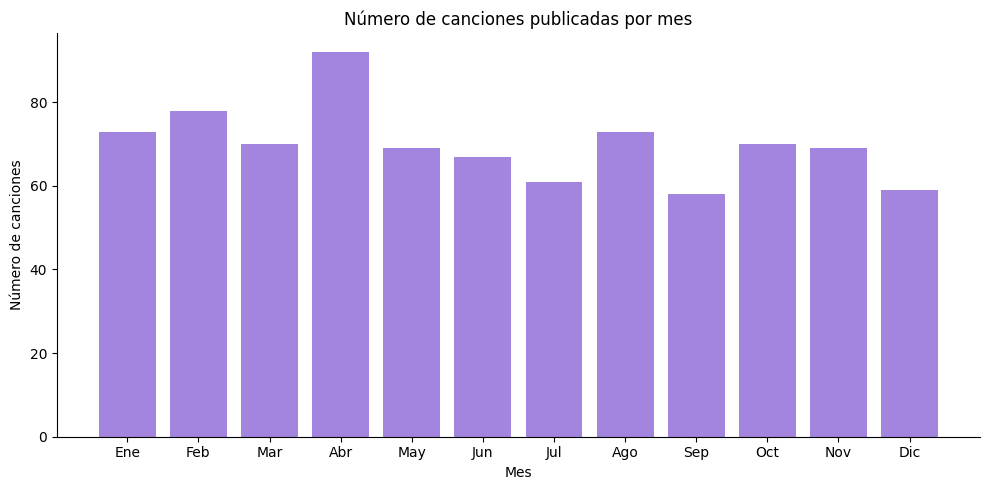

In [ ]:
conteo_mes = (
    df_merged_analysis[df_merged_analysis['anio'] > 1900]
    .groupby('mes')['id_cancion'].count().reset_index()
)
conteo_mes.columns = ['mes', 'canciones']
nombre_meses = ['Ene','Feb','Mar','Abr','May','Jun','Jul','Ago','Sep','Oct','Nov','Dic']
conteo_mes['mes_nombre'] = conteo_mes['mes'].apply(lambda x: nombre_meses[int(x)-1] if 1 <= x <= 12 else str(x))

plt.figure(figsize=(10, 5))
plt.bar(conteo_mes['mes_nombre'], conteo_mes['canciones'], color='mediumpurple', alpha=0.85)
plt.title('Número de canciones publicadas por mes')
plt.xlabel('Mes')
plt.ylabel('Número de canciones')
sns.despine()
plt.tight_layout()
plt.show()

Un patrón relativamente estable a lo largo del año, oscilando entre 58 y 78 publicaciones en la mayoría de los meses. Abril destaca claramente como un outlier al alza, con cerca de 92 canciones publicadas, muy por encima del resto —casi 15-20 canciones más que el segundo mes más alto (Febrero)—, lo que sugiere un evento puntual (campaña, lanzamiento masivo o cierre de trimestre) que impulsó la publicación ese mes. En el extremo opuesto, Septiembre y Diciembre presentan los valores más bajos (58 y 59 respectivamente), marcando un ligero declive hacia el segundo semestre del año. Se aprecia una tendencia descendente moderada desde la primera mitad del año (Ene-Ago, mayoritariamente por encima de 60-70) hacia la segunda mitad (Sep-Dic, con valores algo más bajos y consistentes), aunque sin caídas drásticas.

/tmp/ipykernel_9676/4103904468.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, x='mes_nombre', y='numero_reproducciones', order=nombre_meses, palette='coolwarm')


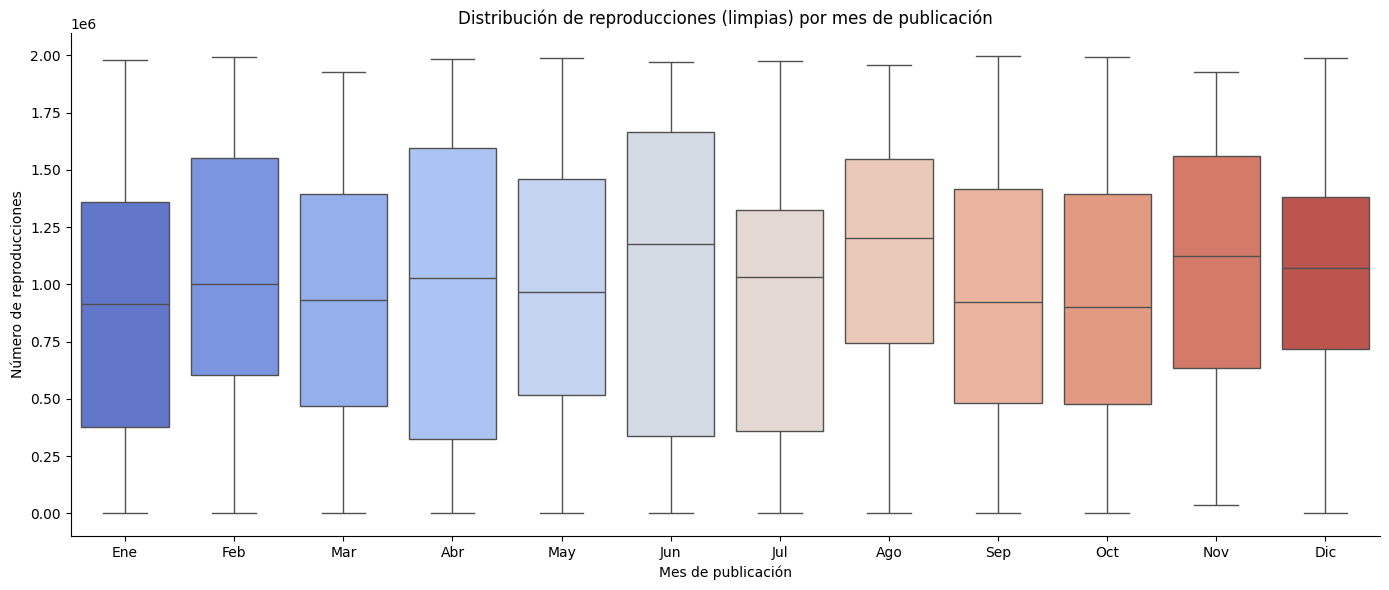

In [ ]:
df_plot = df_merged_analysis[
    (df_merged_analysis['anio'] > 1900) & df_merged_analysis['mes'].between(1, 12)
].copy()
df_plot['mes_nombre'] = df_plot['mes'].apply(lambda x: nombre_meses[int(x)-1])

plt.figure(figsize=(14, 6))
sns.boxplot(data=df_plot, x='mes_nombre', y='numero_reproducciones', order=nombre_meses, palette='coolwarm')
plt.title('Distribución de reproducciones (limpias) por mes de publicación')
plt.xlabel('Mes de publicación')
plt.ylabel('Número de reproducciones')
sns.despine()
plt.tight_layout()
plt.show()


El boxplot muestra la distribución de reproducciones por mes de publicación, revelando una alta variabilidad interna en todos los meses, con rangos intercuartílicos muy amplios y bigotes que en casi todos los casos van desde cerca de 0 hasta prácticamente 2 millones — esto indica que el mes de publicación no determina de forma clara cuántas reproducciones tendrá una canción,dentro de cada mes coexisten canciones con reproducciones muy bajas y muy altas.

Las medianas oscilan en un rango relativamente estrecho (aproximadamente entre 0.90M y 1.20M), con Junio y Agosto destacando por tener las medianas más altas (1.17M y 1.20M respectivamente), mientras que Enero, Marzo, Septiembre y Octubre presentan las medianas más bajas (0.90-0.93M), sugiriendo una ligera ventaja para canciones publicadas a mitad de año.

Los tamaños de las cajas varían: meses como Junio, Agosto y Noviembre muestran cajas más grandes (mayor dispersión entre el 25% y 75% de los datos), mientras que Marzo y Abril tienen cajas relativamente más compactas en su Q1, aunque igualmente con colas largas. No se observan outliers marcados como puntos individuales fuera de los bigotes en ningún mes, lo cual, combinado con el hallazgo previo de baja correlación entre numero_reproducciones y total_reproducciones, refuerza la idea de que esta variable tiene un comportamiento muy disperso y poco predecible por temporalidad.






In [ ]:
# Convertir la columna a numérico (fuerza NaN en los valores que no se puedan convertir)
df_popularidadycancion['numero_reproducciones'] = pd.to_numeric(
    df_popularidadycancion['numero_reproducciones'], errors='coerce'
)

# Opcional: eliminar filas donde la conversión falló (quedaron como NaN)
df_popularidadycancion = df_popularidadycancion.dropna(subset=['numero_reproducciones'])

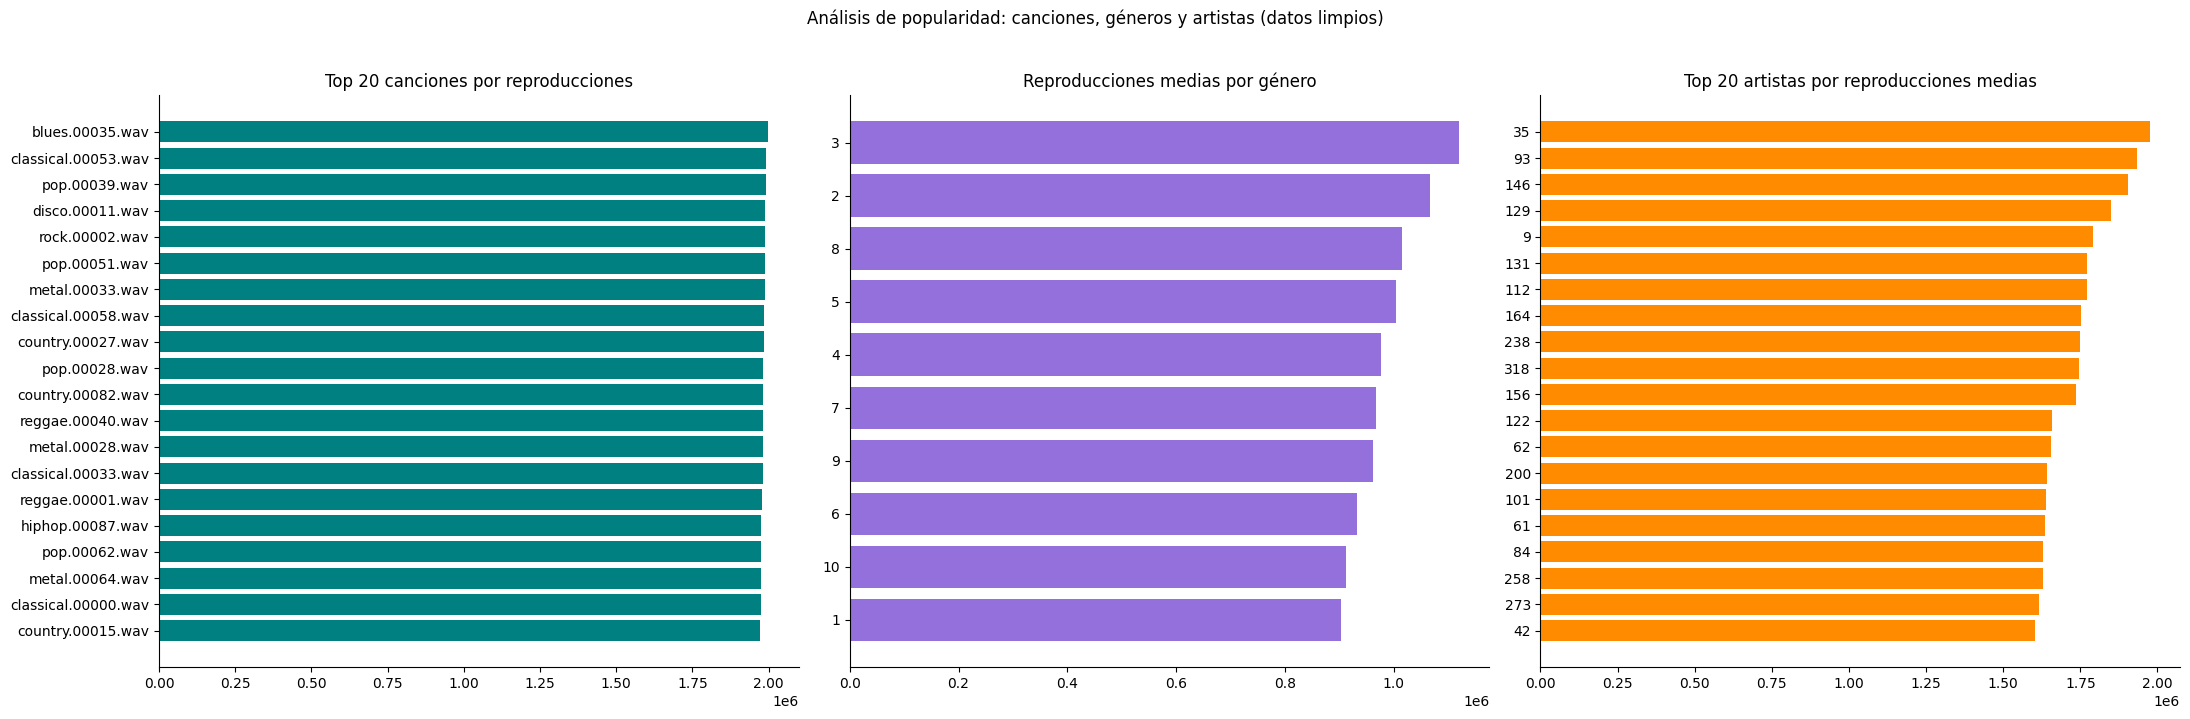

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(22, 7))

df_top_canciones = df_popularidadycancion.nlargest(20, 'numero_reproducciones')
axes[0].barh(df_top_canciones['id_cancion'].astype(str), df_top_canciones['numero_reproducciones'], color='teal')
axes[0].invert_yaxis()
axes[0].set_title('Top 20 canciones por reproducciones')

df_genero_top = (
    df_popularidadycancion.groupby(col_genero)['numero_reproducciones']
    .mean().sort_values(ascending=True).reset_index()
)
axes[1].barh(df_genero_top[col_genero].astype(str), df_genero_top['numero_reproducciones'], color='mediumpurple')
axes[1].set_title('Reproducciones medias por género')

df_artista_top = (
    df_popularidadycancion.groupby(col_autor)['numero_reproducciones']
    .mean().sort_values(ascending=False).head(20).sort_values(ascending=True).reset_index()
)
axes[2].barh(df_artista_top[col_autor].astype(str), df_artista_top['numero_reproducciones'], color='darkorange')
axes[2].set_title('Top 20 artistas por reproducciones medias')

for ax in axes:
    sns.despine(ax=ax)
plt.suptitle('Análisis de popularidad: canciones, géneros y artistas (datos limpios)', y=1.02)
plt.tight_layout()
plt.show()

* **Top 20 canciones por reproducciones:** este gráfico muestra un patrón muy llamativo, las 20 canciones con más reproducciones presentan valores prácticamente idénticos, todas rozando el máximo de aproximadamente 2,000,000, sin apenas diferencia visual entre la primera posición y la vigésima. Esto sugiere que no existe una jerarquía real de popularidad en el extremo superior, sino que estas canciones probablemente están tocando un techo o límite estructural en la variable numero_reproducciones, coherente con el rango 0-2M observado en los histogramas anteriores.

* **Reproducciones medias por género:** se observa una jerarquía gradual entre géneros. El género 3 lidera claramente con una media cercana a 1.15M de reproducciones, seguido de una caída progresiva y escalonada hasta el género 1, que presenta la media más baja, en torno a 0.90M. La diferencia entre el género top y el de menor rendimiento es de aproximadamente 250,000 reproducciones, un rango moderado que indica cierta variabilidad entre géneros, pero sin un dominio aplastante de ninguno sobre el resto.

* **Top 20 artistas por reproducciones medias:** Existe un artista claramente en cabeza (35), con una media cercana a 2.0M, pero a partir de ahí la caída es suave y progresiva hasta el puesto 20, que ronda 1.6M, sin el efecto de saturación o empate técnico visto en las canciones individuales. Esto indica que, al calcular la media por artista (agregando varias canciones), también se atenúa el posible efecto del tope de datos, resultando en un ranking con más capacidad de diferenciación real entre artistas. La diferencia entre el primer y el vigésimo puesto (~400,000 reproducciones) es considerablemente más amplia que la del top de canciones, reforzando que esta vista ofrece información más útil para identificar quiénes son realmente los artistas más exitosos.

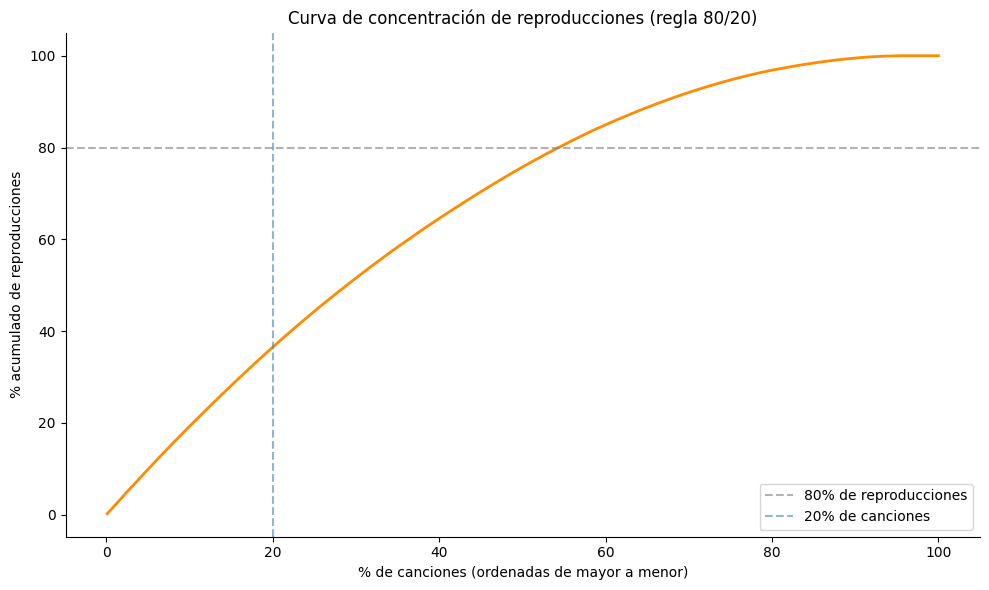

In [ ]:
df_sorted = df_popularidadycancion.sort_values('numero_reproducciones', ascending=False).reset_index(drop=True)
df_sorted['pct_canciones'] = (df_sorted.index + 1) / len(df_sorted) * 100
df_sorted['pct_reproducciones_acum'] = df_sorted['numero_reproducciones'].cumsum() / df_sorted['numero_reproducciones'].sum() * 100

plt.figure(figsize=(10, 6))
plt.plot(df_sorted['pct_canciones'], df_sorted['pct_reproducciones_acum'], color='darkorange', linewidth=2)
plt.axhline(80, color='gray', linestyle='--', alpha=0.6, label='80% de reproducciones')
plt.axvline(20, color='steelblue', linestyle='--', alpha=0.6, label='20% de canciones')
plt.title('Curva de concentración de reproducciones (regla 80/20)')
plt.xlabel('% de canciones (ordenadas de mayor a menor)')
plt.ylabel('% acumulado de reproducciones')
plt.legend()
sns.despine()
plt.tight_layout()
plt.show()

La curva de Lorenz analiza si se cumple la regla 80/20 (Pareto) en las reproducciones del dataset. El 20% de las canciones top solo acumula un 37% de las reproducciones, muy lejos del 80% esperado, por lo que la regla de Pareto no se cumple. Para alcanzar el 80% de reproducciones acumuladas es necesario llegar hasta el 55% de las canciones, más del doble de lo previsto por Pareto. La forma de la curva, cercana a una diagonal y poco cóncava, indica una distribución relativamente equitativa en lugar de una concentración fuerte en pocos títulos. Este resultado es coherente con el histograma casi uniforme de numero_reproducciones observado previamente. En consumo musical real, lo habitual es una fuerte concentración tipo long-tail, donde pocos "hits" dominan las reproducciones. La ausencia de ese patrón aquí es una señal atípica para datos de streaming genuinos. Esto refuerza sospechas previas sobre la naturaleza de los datos, como el tope aparente en 2M reproducciones y la baja correlación con total_reproducciones. En conjunto, todo apunta a que el dataset podría ser sintético o generado artificialmente, no un reflejo real de comportamiento de usuarios. Se recomienda validar el origen y proceso de generación de los datos antes de extraer conclusiones de negocio sobre popularidad o consumo.